# Meridional Heat Transport

Using advective and parameterised heat transport diagnostics.

Note I didn't deal with the tripole properly, so zonal averaging is over the x coordinate of the model. This is greyed out in the plots as a reminder.

Finally, not time averages just use a simple `.mean('time')`, which does not capture the fact that different months have different lengths.

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/12

Code drawn heavily from [cosima recipes MHT example](https://github.com/COSIMA/cosima-recipes/blob/main/03-Mains/Meridional_heat_transport.ipynb) and [ACCESS-OM2 MHT eval figure](https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/tree/master/figures/meridional_heat_transport).

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json"
papermill = True
cwd = (
    "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/"
)
nbname = "MeridionalHeatTransport.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import xarray as xr
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import numpy as np
from pandas import read_csv

In [5]:
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()   # no-op on healthy conda envs
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42539,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45319,Total threads: 1
Dashboard: http://127.0.0.1:36887/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:46875,


In [6]:
IAF = esm_file.find('iaf') > 0
IAF

True

### Load ACCESS-OM3-25km MHT diagnostics 

In [7]:
from exptdata_access import get_exptname_from_path
exptname = get_exptname_from_path(esm_file)

In [8]:
catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/access-om3-output/access-om3-025/MC_25km_jra_ryf-1.0-beta/experiment_datastore.json',
                esm_file,
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
                '/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json',  # 100km RYF spin-up
                '/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json',  # ACCESS-CM3
            ]
if not IAF and "cm3" not in exptname.lower():
    # RYF: the IAF and CM3 comparison runs above don't share model years with an RYF run
    catalogs = [c for c in catalogs if c == esm_file or ("iaf" not in c and "cm3" not in c.lower())]
catalogs

['/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json',
 '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
 '/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json',
 '/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json']

In [9]:
datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c, columns_with_iterables=['variable'])
              for c in catalogs }
datastores

{'MC_100km_jra_iaf+wombatlite-test1-e1de2a94': <experiment_datastore catalog with 24 dataset(s) from 11531 asset(s)>,
 'MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415': <datastore catalog with 24 dataset(s) from 16791 asset(s)>,
 'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c': <experiment_datastore catalog with 15 dataset(s) from 8540 asset(s)>,
 'cm3-run-27-07-2026-PD-control': <cm3-datastore catalog with 22 dataset(s) from 7000 asset(s)>}

In [10]:
datastore = datastores[exptname]

In [11]:
# ACCESS-OM2-025 experiment
# use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258
if IAF:
    om2expt = '025deg_jra55_iaf_omip2_cycle1'
else:
    om2expt = '025deg_jra55_ryf9091_gadi'
om2cat = intake.cat.access_nri[om2expt]

### Load ACCESS-OM3-25km and ACCESS-OM2-025 wind stress diagnostics 

In [12]:
fields = { # key is OM3 name, value is OM2 name
    'T_ady_2d': None,  # residual mean advective heat transport, vertically integrated
    'T_diffy_2d': None,  # neutral diffusive heat transport, vertically integrated
    # 'T_hbd_diffy_2d': None,  # horizontal boundary diffusive heat transport, vertically integrated (not present)
}
fields

{'T_ady_2d': None, 'T_diffy_2d': None}

In [13]:
# from https://github.com/COSIMA/cosima-recipes/blob/main/Cooking-Lessons-101-Tutorials/ACCESS-NRI_Intake_Catalog.ipynb
# Speeding up opening your datasets
# Try passing the following argument to your to_dask or to_dataset_dict call:
# See the xarray documentation on Reading multi-file datasets for more details about these arguments.
# https://docs.xarray.dev/en/stable/user-guide/io.html#reading-multi-file-datasets

xarray_combine_by_coords_kwargs=dict(
    compat="override",
    data_vars="minimal",
    coords="minimal"
)

In [14]:
# load data
data = dict()
for k, om2 in fields.items():
    print(k)
    try:
        d = { n: ds.search(variable=k, frequency='1mon', variable_cell_methods='.*time: mean.*') for n, ds in datastores.items() }
        d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs,
                            xarray_open_kwargs = dict(chunks={"time": -1}, decode_timedelta=True)
                           ) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
    except:
        print(f'{k} failed')
        continue
    if om2 is None: # add access-om2 data,with variable name changed to match om3
        d2 = {}
    else:
        d2 = {om2expt: om2cat.search(variable=om2, frequency=d[list(d.keys())[0]].attrs['intake_esm_attrs:frequency']).to_dask().rename({om2: k})}
    data[k] = d2 | d

if IAF or "cm3" in exptname.lower():  # common calendar for obs overlays
    for vname, d in data.items():
        for expt in d.keys():
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

# RYF spin-up runs use a synthetic calendar (e.g. starting ~1900s) unrelated to real
# forcing dates, so their time axis does not overlap the IAF experiments at all.
# Relabel onto the primary experiment's real time axis so the RYF run plots on the
# same timescale as the IAF runs. Only applied to the RYF experiment.
_ryf_expt = "MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c"
for _vname, _d in data.items():
    if _ryf_expt not in _d or exptname not in _d:
        continue
    _ref = _d[exptname].time
    _rds = _d[_ryf_expt]
    _n = min(_rds.sizes["time"], _ref.sizes["time"])
    _d[_ryf_expt] = (_rds.isel(time=slice(None, _n))
                         .assign_coords(time=("time", _ref.isel(time=slice(None, _n)).values)))


T_ady_2d


T_diffy_2d


In [15]:
T_ady_2d = data['T_ady_2d'][exptname]
T_diffy_2d = data['T_diffy_2d'][exptname]

In [16]:
if exptname == '25km-iaf-test-for-AK-expt-7df5ef4c':
# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
    T_ady_2d = T_ady_2d.isel(yq=slice(10, None))
    T_diffy_2d= T_diffy_2d.isel(yq=slice(10, None))

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md successfully.
CPU times: user 1.41 s, sys: 808 ms, total: 2.22 s
Wall time: 2.32 s


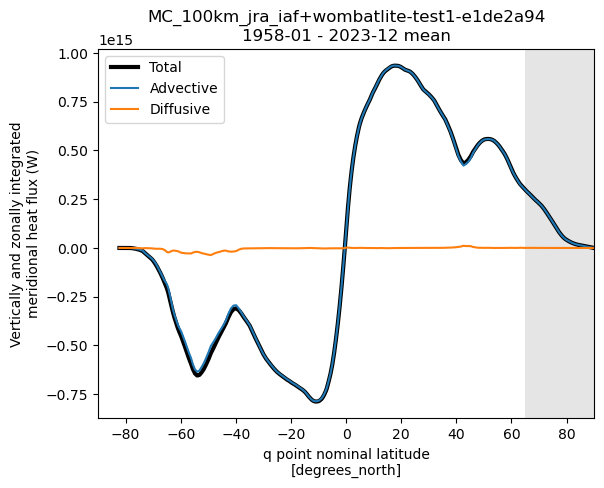

In [17]:
%%time
# quick and dirty plot
T_ady_2d_sumx = T_ady_2d.T_ady_2d.sum('xh').mean('time').load()
T_diffy_2d_sumx = T_diffy_2d.T_diffy_2d.sum('xh').mean('time').load()

(T_ady_2d_sumx + T_diffy_2d_sumx).plot(label = 'Total', color = 'k', linewidth=3)
T_ady_2d_sumx.plot(label = 'Advective')
T_diffy_2d_sumx.plot(label = 'Diffusive')

plt.xlim(-90, 90)
plt.axvspan(65, 90, facecolor="k", alpha=0.1)  # shade tripolar region, where sum is not zonal
plt.legend()
plt.ylabel('Vertically and zonally integrated\nmeridional heat flux (W)')
plt.title(f"{exptname}\n{T_ady_2d.time.values[0].strftime('%Y-%m')} - {T_ady_2d.time.values[-1].strftime('%Y-%m')} mean")
mkmd.savefig(plt.gcf(), "Meridional Heat Transport", f"Zonally-integrated meridional heat transport for {exptname} (advective + diffusive components).")

In [18]:
import re

def mlabel(e):
    # resolution is taken from the experiment name so 100km runs are not mislabelled as 25km
    res = re.search(r"\d+km", e).group() if re.search(r"\d+km", e) else "25km"
    return f"ACCESS-CM3-{res} {e}" if "cm3" in e.lower() else f"ACCESS-OM3-{res} {e}"

data['MHT'] = {
    e: data['T_ady_2d'][e].T_ady_2d.sum('xh') + data['T_diffy_2d'][e].T_diffy_2d.sum('xh')
    for e in datastores.keys()
}

### Load ACCESS-OM2-025 MHT diagnostic 

(advective heat flux `temp_yflux_adv_int_z` plus parameterised `temp_yflux_ndiffuse`, `temp_yflux_gm`, `temp_yflux_submeso`)

Using OMIP cycle 1, following COSIMA recipes example https://github.com/COSIMA/cosima-recipes/blob/main/03-Mains/Meridional_heat_transport.ipynb

Also help from https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/meridional_heat_transport/Meridional_Heat_Transport.ipynb

In [19]:
catalog = intake.cat.access_nri
experiment = '025deg_jra55_iaf_omip2_cycle1'
cat_subset = catalog[experiment]

var_search = cat_subset.search(variable='temp_yflux_adv_int_z')
darray = var_search.to_dask(xarray_open_kwargs={
            "decode_timedelta": False,
            'chunks': "auto"
        })
temp_yflux_adv_int_z_cycle1 = darray['temp_yflux_adv_int_z']

var_search = cat_subset.search(variable='temp_yflux_gm_int_z')
darray = var_search.to_dask(xarray_open_kwargs={
            "decode_timedelta": False,
            'chunks': "auto"
        })
temp_yflux_gm_int_z_cycle1 = darray['temp_yflux_gm_int_z']

var_search = cat_subset.search(variable='temp_yflux_ndiffuse_int_z')
darray = var_search.to_dask(xarray_open_kwargs={
            "decode_timedelta": False,
            'chunks': "auto"
        })
temp_yflux_ndiffuse_int_z_cycle1 = darray['temp_yflux_ndiffuse_int_z']

var_search = cat_subset.search(variable='temp_yflux_submeso_int_z')
darray = var_search.to_dask(xarray_open_kwargs={
            "decode_timedelta": False,
            'chunks': "auto"
        })
temp_yflux_submeso_int_z_cycle1 = darray['temp_yflux_submeso_int_z']

In [20]:
# common calendar for obs overlays (and cftime times, which the titles below rely on)
temp_yflux_adv_int_z_cycle1 = temp_yflux_adv_int_z_cycle1.convert_calendar("proleptic_gregorian", use_cftime=True)
temp_yflux_gm_int_z_cycle1 = temp_yflux_gm_int_z_cycle1.convert_calendar("proleptic_gregorian", use_cftime=True)
temp_yflux_ndiffuse_int_z_cycle1 = temp_yflux_ndiffuse_int_z_cycle1.convert_calendar("proleptic_gregorian", use_cftime=True)
temp_yflux_submeso_int_z_cycle1 = temp_yflux_submeso_int_z_cycle1.convert_calendar("proleptic_gregorian", use_cftime=True)

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md successfully.
CPU times: user 6.28 s, sys: 4.38 s, total: 10.7 s
Wall time: 20.2 s


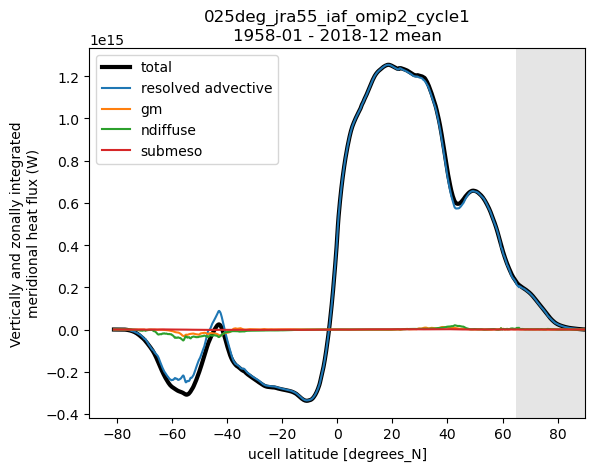

In [21]:
%%time
# quick and dirty plot
temp_yflux_adv_int_z_cycle1_sumx = temp_yflux_adv_int_z_cycle1.sum('xt_ocean').mean('time').load()
temp_yflux_gm_int_z_cycle1_sumx = temp_yflux_gm_int_z_cycle1.sum('xt_ocean').mean('time').load()
temp_yflux_ndiffuse_int_z_cycle1_sumx = temp_yflux_ndiffuse_int_z_cycle1.sum('xt_ocean').mean('time').load()
temp_yflux_submeso_int_z_cycle1_sumx = temp_yflux_submeso_int_z_cycle1.sum('xt_ocean').mean('time').load()

(temp_yflux_adv_int_z_cycle1_sumx
                 + temp_yflux_gm_int_z_cycle1_sumx \
                 + temp_yflux_ndiffuse_int_z_cycle1_sumx \
                 + temp_yflux_submeso_int_z_cycle1_sumx).plot(color = 'k', linewidth=3, label = 'total')
temp_yflux_adv_int_z_cycle1_sumx.plot(label = 'resolved advective')
temp_yflux_gm_int_z_cycle1_sumx.plot(label = 'gm')
temp_yflux_ndiffuse_int_z_cycle1_sumx.plot(label = 'ndiffuse')
temp_yflux_submeso_int_z_cycle1_sumx.plot(label = 'submeso')

plt.xlim(-90, 90)
plt.axvspan(65, 90, facecolor="k", alpha=0.1)  # shade tripolar region, where sum is not zonal
plt.legend()
plt.ylabel('Vertically and zonally integrated\nmeridional heat flux (W)')
plt.title(f"{experiment}\n{temp_yflux_adv_int_z_cycle1.time.values[0].strftime('%Y-%m')} - {temp_yflux_adv_int_z_cycle1.time.values[-1].strftime('%Y-%m')} mean")
mkmd.savefig(plt.gcf(), "Meridional Heat Transport", f"Zonally-integrated meridional heat transport for ACCESS-OM2-025 {experiment} (advective, GM, ndiffuse, submeso components).")

In [22]:
MHT_OM2_025 = temp_yflux_adv_int_z_cycle1.sum('xt_ocean') \
                 + temp_yflux_gm_int_z_cycle1.sum('xt_ocean') \
                 + temp_yflux_ndiffuse_int_z_cycle1.sum('xt_ocean') \
                 + temp_yflux_submeso_int_z_cycle1.sum('xt_ocean')

# ACCESS-CM2 cj877 control: first 600 months (50 years, matching CM3).
import glob
# Each file contains six months; two files per year, ordered by year/month.
def _cm2_yflux(v):
    files = sorted(glob.glob(f'/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-2d-{v}-1-monthly-mean-ym_*.nc'))[:100]
    if len(files) != 100:
        raise FileNotFoundError(f'Expected 100 cj877 files for {v}, found {len(files)}')
    return xr.open_mfdataset(files, combine="by_coords", parallel=True, chunks={"time": 6},
                             decode_timedelta=False, use_cftime=True,
                             data_vars="minimal", coords="minimal", compat="override")[v]

MHT_CM2_025 = sum(_cm2_yflux(v).sum('xt_ocean')
                  for v in ['temp_yflux_adv_int_z', 'temp_yflux_gm_int_z',
                            'temp_yflux_ndiffuse_int_z', 'temp_yflux_submeso_int_z'])
MHT_CM2_025_mean = (MHT_CM2_025.mean('time')/1e15).load()  # CM2 control years are not aligned with IAF years


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a112e7d280>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x146ef23e77d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a1084417c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15105772d820>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ac37895190>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14db7813b6e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14db7aa767b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14db764901a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1471fef4ed20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1471fabd0500>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


### Trim to a consistent time range

In [23]:
if IAF or "cm3" in exptname.lower():
    # find largest overlapping time range

    # latest start date in data
    datastart = np.max([ data['MHT'][e].time.values[0] for e in datastores.keys() ])
    datastart = max(datastart, MHT_OM2_025.time.values[0])

    # earliest end date in data
    datastop = np.min([ data['MHT'][e].time.values[-1] for e in datastores.keys() ])
    datastop = min(datastop, MHT_OM2_025.time.values[-1])

    om2timeslice = None  # set below
else:
    # RYF: model years don't correspond to the IAF years of the OM2 run (the OM2 RYF
    # control has no heat transport diagnostics), so use the common model years of the
    # OM3 runs, and the whole OM2 IAF record
    datastart = np.max([ data['MHT'][e].time.values[0] for e in datastores.keys() ])
    datastop = np.min([ data['MHT'][e].time.values[-1] for e in datastores.keys() ])
    om2timeslice = slice(None, None)

print ('common data range:', datastart, ' to ', datastop)

# bracket to start/end of year
datestart = cftime.datetime(cftime.to_tuple(datastart)[0],  1, 1, calendar=datastop.calendar)
datestop  = cftime.datetime(cftime.to_tuple(datastop)[0], 12, 31, 23, 59, 59, calendar=datastop.calendar)

timeslice = slice(datestart, datestop)
if om2timeslice is None:
    om2timeslice = timeslice
    om2label = f'ACCESS-OM2-025 {experiment}'
else:
    _om2years = MHT_OM2_025.time.dt.year.values
    om2label = f'ACCESS-OM2-025 {experiment} ({_om2years[0]}-{_om2years[-1]})'
timeslice

common data range: 1990-01-16 12:00:00  to  2007-12-16 12:00:00


slice(cftime.datetime(1990, 1, 1, 0, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.datetime(2007, 12, 31, 23, 59, 59, 0, calendar='proleptic_gregorian', has_year_zero=True), None)

In [24]:
%%time
MHT_OM2_025 = MHT_OM2_025.sel(time=om2timeslice).load()
MHT_OM3_25k = { e: data['MHT'][e].sel(time=timeslice).load() for e in datastores.keys()}

CPU times: user 12 s, sys: 5.88 s, total: 17.9 s
Wall time: 21 s


### Plot time mean

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md successfully.
CPU times: user 376 ms, sys: 145 ms, total: 521 ms
Wall time: 410 ms


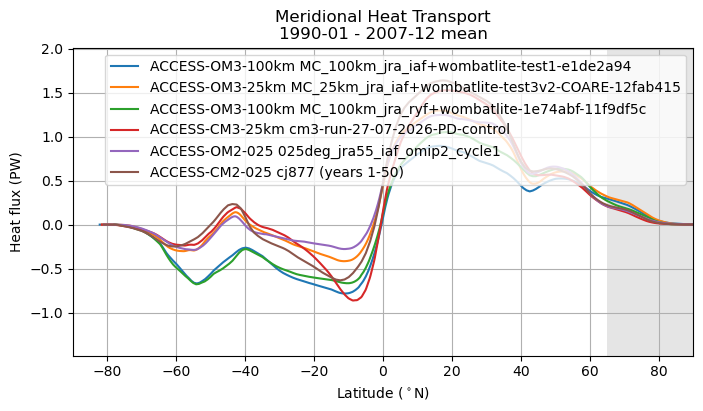

In [25]:
%%time
fig, axes = plt.subplots(figsize = (8,4))

for e, MHT in MHT_OM3_25k.items():
    (MHT.mean('time')/1e15).plot(x = 'yq', label = mlabel(e))

(MHT_OM2_025.mean('time')/1e15).plot(x = 'yu_ocean', label = om2label)
MHT_CM2_025_mean.plot(x = 'yu_ocean', label = 'ACCESS-CM2-025 cj877 (years 1-50)')

plt.xlim(-90, 90)
plt.axvspan(65, 90, facecolor="k", alpha=0.1)  # shade tripolar region, where sum is not zonal
plt.legend()
plt.ylabel('Heat flux (PW)')
plt.title(f"Meridional Heat Transport\n{datestart.strftime('%Y-%m')} - {datestop.strftime('%Y-%m')} mean")
plt.xlabel('Latitude ($^\circ$N)')
plt.ylim(-1.49,2.01)

plt.grid()
mkmd.savefig(fig, "Meridional Heat Transport", "Meridional heat transport time mean, all experiments.")

### Plot time mean + individual years

CPU times: user 462 ms, sys: 290 ms, total: 752 ms
Wall time: 597 ms


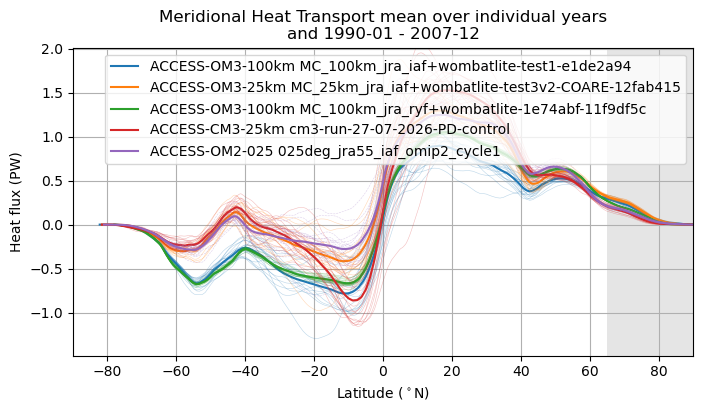

In [26]:
%%time
fig, axes = plt.subplots(figsize = (8,4))

for e, MHT in MHT_OM3_25k.items():
    p = (MHT.mean('time')/1e15).plot(x = 'yq',label = mlabel(e))
    (MHT.groupby('time.year').mean('time')/1e15).plot.line(x = 'yq', color = p[-1].get_color(),#'C0',
                                                                             alpha = 0.3, lw = 0.4,
                                                                             add_legend = False)
p = (MHT_OM2_025.mean('time')/1e15).plot(x = 'yu_ocean',label = om2label)
(MHT_OM2_025.groupby('time.year').mean('time')/1e15).plot.line(x = 'yu_ocean', color = p[-1].get_color(),#'C1',
                                                                         alpha = 0.3, lw = 0.4,ls = '--',                                                                         add_legend = False)

plt.xlim(-90, 90)
plt.axvspan(65, 90, facecolor="k", alpha=0.1)  # shade tripolar region, where sum is not zonal
plt.legend()
plt.ylabel('Heat flux (PW)')
plt.title(f"Meridional Heat Transport mean over individual years\nand {datestart.strftime('%Y-%m')} - {datestop.strftime('%Y-%m')}")
plt.xlabel('Latitude ($^\circ$N)')
plt.ylim(-1.49,2.01)
plt.grid()

### Add more models/cycles
All 6 025deg OMIP cycles + 01 deg

In [27]:
%%time
def find_MHT_OM2(expt, gm = True, ndiffuse = True, submeso = True):
    catalog = intake.cat.access_nri
    experiment = expt
    cat_subset = catalog[experiment]
    
    var_search = cat_subset.search(variable='temp_yflux_adv_int_z')
    darray = var_search.to_dask(xarray_open_kwargs={
                "decode_timedelta": False,
                'chunks': "auto"
            })
    temp_yflux_adv_int_z_cycle1 = darray['temp_yflux_adv_int_z']
    if gm:
        try:
            var_search = cat_subset.search(variable='temp_yflux_gm_int_z')
            temp_yflux_gm_int_z_cycle1 = var_search.to_dask(xarray_open_kwargs={
                        "decode_timedelta": False,
                        'chunks': "auto"
                    }).temp_yflux_gm_int_z
            
        except ValueError:
            print('no temp_yflux_gm_int_z in ',expt)
            gm = False
    if ndiffuse:
        try:
            var_search = cat_subset.search(variable='temp_yflux_ndiffuse_int_z')
            temp_yflux_ndiffuse_int_z_cycle1 = var_search.to_dask(xarray_open_kwargs={
                        "decode_timedelta": False,
                        'chunks': "auto"
                    }).temp_yflux_ndiffuse_int_z
        except ValueError:
            print('no temp_yflux_ndiffuse_int_z in ',expt)
            ndiffuse = False
    if submeso:
        try:
            var_search = cat_subset.search(variable='temp_yflux_submeso_int_z')
            temp_yflux_submeso_int_z_cycle1 = var_search.to_dask(xarray_open_kwargs={
                        "decode_timedelta": False,
                        'chunks': "auto"
                    }).temp_yflux_submeso_int_z
        except ValueError:
            print('no temp_yflux_submeso_int_z in ',expt)
            submeso = False

        
    MHT_OM2_025 = temp_yflux_adv_int_z_cycle1.sum('xt_ocean') 
    if gm:
        MHT_OM2_025 += temp_yflux_gm_int_z_cycle1.sum('xt_ocean')
    if ndiffuse:
        MHT_OM2_025 += temp_yflux_ndiffuse_int_z_cycle1.sum('xt_ocean')
    if submeso:
        MHT_OM2_025 += temp_yflux_submeso_int_z_cycle1.sum('xt_ocean')
    return MHT_OM2_025


experiment = '025deg_jra55_iaf_omip2_cycle2'
MHT_OM2_025_cycle2 = find_MHT_OM2(experiment).convert_calendar("proleptic_gregorian", use_cftime=True)
MHT_OM2_025_cycle2 = MHT_OM2_025_cycle2.sel(time=om2timeslice).load()
print(experiment, len(darray.time))

experiment = '025deg_jra55_iaf_omip2_cycle3'
MHT_OM2_025_cycle3 = find_MHT_OM2(experiment).convert_calendar("proleptic_gregorian", use_cftime=True)
MHT_OM2_025_cycle3 = MHT_OM2_025_cycle3.sel(time=om2timeslice).load()
print(experiment, len(darray.time))

experiment = '025deg_jra55_iaf_omip2_cycle4'
MHT_OM2_025_cycle4 = find_MHT_OM2(experiment).convert_calendar("proleptic_gregorian", use_cftime=True)
MHT_OM2_025_cycle4 = MHT_OM2_025_cycle4.sel(time=om2timeslice).load()
print(experiment, len(darray.time))

experiment = '025deg_jra55_iaf_omip2_cycle5'
MHT_OM2_025_cycle5 = find_MHT_OM2(experiment).convert_calendar("proleptic_gregorian", use_cftime=True)
MHT_OM2_025_cycle5 = MHT_OM2_025_cycle5.sel(time=om2timeslice).load()
print(experiment, len(darray.time))

experiment = '025deg_jra55_iaf_omip2_cycle6'
MHT_OM2_025_cycle6 = find_MHT_OM2(experiment).convert_calendar("proleptic_gregorian", use_cftime=True)
MHT_OM2_025_cycle6 = MHT_OM2_025_cycle6.sel(time=om2timeslice).load()
print(experiment, len(darray.time))

experiment = '01deg_jra55v140_iaf_cycle3'
MHT_OM2_01 = find_MHT_OM2(experiment, gm = False, ndiffuse = False).convert_calendar("proleptic_gregorian", use_cftime=True)
MHT_OM2_01 = MHT_OM2_01.sel(time=om2timeslice).load()
print(experiment, len(darray.time))


025deg_jra55_iaf_omip2_cycle2 732


025deg_jra55_iaf_omip2_cycle3 732


025deg_jra55_iaf_omip2_cycle4 732


025deg_jra55_iaf_omip2_cycle5 732


025deg_jra55_iaf_omip2_cycle6 732


no temp_yflux_submeso_int_z in  01deg_jra55v140_iaf_cycle3


01deg_jra55v140_iaf_cycle3 732
CPU times: user 48.8 s, sys: 32.9 s, total: 1min 21s
Wall time: 1min 48s


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md successfully.


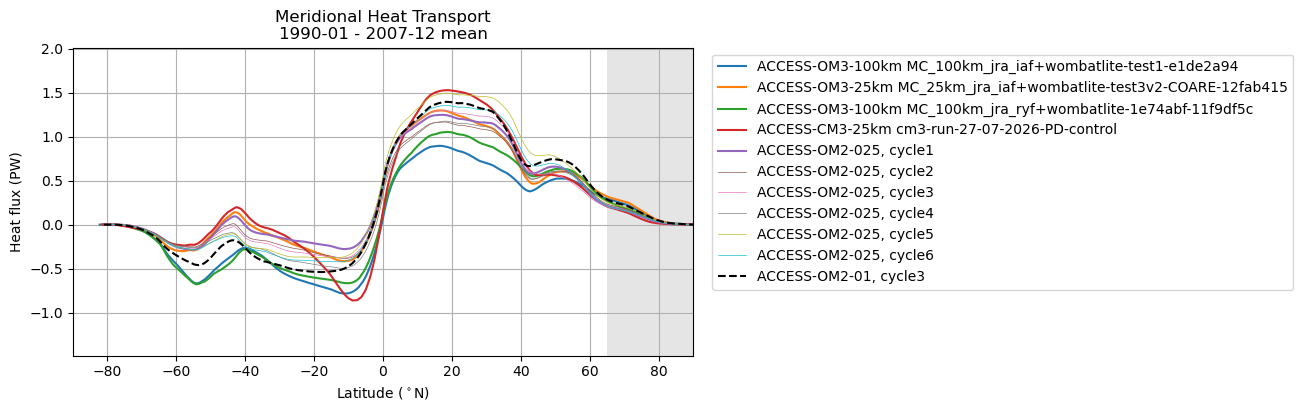

In [28]:
fig, axes = plt.subplots(figsize = (8,4))

for e, MHT in MHT_OM3_25k.items():
    (MHT.mean('time')/1e15).plot(x = 'yq',label = mlabel(e))
(MHT_OM2_025.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-025, cycle1')
(MHT_OM2_025_cycle2.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-025, cycle2',lw = 0.5)
(MHT_OM2_025_cycle3.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-025, cycle3',lw = 0.5)
(MHT_OM2_025_cycle4.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-025, cycle4',lw = 0.5)
(MHT_OM2_025_cycle5.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-025, cycle5',lw = 0.5)
(MHT_OM2_025_cycle6.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-025, cycle6',lw = 0.5)
(MHT_OM2_01.mean('time')/1e15).plot(x = 'yu_ocean',label = 'ACCESS-OM2-01, cycle3',color = 'k', ls = '--')

plt.xlim(-90, 90)
plt.axvspan(65, 90, facecolor="k", alpha=0.1)  # shade tripolar region, where sum is not zonal
plt.legend(loc = 'upper left', bbox_to_anchor = (1.02,1))
plt.ylabel('Heat flux (PW)')
plt.title(f"Meridional Heat Transport\n{datestart.strftime('%Y-%m')} - {datestop.strftime('%Y-%m')} mean")
plt.xlabel('Latitude ($^\circ$N)')
plt.ylim(-1.49,2.01)

plt.grid()
mkmd.savefig(fig, "Meridional Heat Transport", "Meridional heat transport across all ACCESS-OM2-025 OMIP cycles, ACCESS-OM2-01 cycle3, and the CM2 reference.")

### Compare to estimates from observations/reanalysis

In [29]:
# TODO: use data from PanChengStortoMayerGulevLiLyuZhengYuan2026a
# https://dx.doi.org/10.1175/JCLI-D-25-0522.1

In [30]:
# Trenberth, K. E., Zhang, Y., Fasullo, J. T., and Cheng, L. (2019). Observation- based estimates of global and basin ocean meridional heat transport time series. Journal of Climate, 32(14):4567–4583.
# http://dx.doi.org/10.1175/JCLI-D-18-0872.1
# Fig. 6a_Mean annual cycle of ensemble mean MHT plus sea ice MHT (PW)
# for the global ocean (latitude 89.5S - 89.5N),
# January - December and annual mean, missing is MMM, every 1 degree
filename = '/g/data/ik11/observations/TrenberthZhangFasulloCheng2019/Fig_6a_2000_2016_monthly_ZonalSum_MeanAnnualCycle_globe_0-2000m_ensemble_mean_withSeaIce.txt'
TZFC19 = read_csv(filename, delimiter='\s+', skiprows=3, na_values='MMM',
                 names=['Lat', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Annual'])

# check that final column is in fact the annual mean
cols = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
print(set(TZFC19['Annual'] - round(TZFC19[cols].sum(axis=1)/12, 2)))

TZFC19

{0.0, -0.009999999999999898, 0.010000000000000009, -0.010000000000000009}


,Lat,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Annual
0,-76.5,-0.38,-0.28,-0.18,-0.00,0.28,0.60,0.64,0.33,0.01,-0.23,-0.36,-0.42,0.00
1,-75.5,-0.38,-0.29,-0.20,-0.02,0.27,0.59,0.62,0.32,0.00,-0.24,-0.37,-0.42,-0.01
2,-74.5,-0.38,-0.30,-0.21,-0.03,0.25,0.57,0.61,0.31,-0.01,-0.24,-0.37,-0.42,-0.02
3,-73.5,-0.38,-0.30,-0.23,-0.05,0.23,0.56,0.59,0.29,-0.02,-0.25,-0.38,-0.42,-0.03
4,-72.5,-0.37,-0.31,-0.26,-0.08,0.21,0.53,0.57,0.27,-0.04,-0.26,-0.38,-0.41,-0.04
5,-71.5,-0.36,-0.31,-0.28,-0.11,0.18,0.51,0.54,0.24,-0.06,-0.28,-0.39,-0.41,-0.06
6,-70.5,-0.35,-0.31,-0.31,-0.14,0.15,0.48,0.52,0.22,-0.08,-0.29,-0.39,-0.40,-0.08
7,-69.5,-0.33,-0.31,-0.33,-0.19,0.11,0.45,0.49,0.19,-0.10,-0.31,-0.40,-0.39,-0.09
8,-68.5,-0.30,-0.31,-0.36,-0.24,0.06,0.41,0.45,0.16,-0.13,-0.33,-0.41,-0.38,-0.12
9,-67.5,-0.28,-0.30,-0.39,-0.31,-0.01,0.36,0.41,0.12,-0.16,-0.35,-0.41,-0.37,-0.14


In [31]:
# Fasullo, J. T. and K. E. Trenberth, 2008: The annual cycle of the energy budget: Meridional structures and poleward transports, J. Clim, 21, 10, 2314-2326.
# http://dx.doi.org/10.1175/2007JCLI1936.1
filename = '/g/data3/ik11/from_hh5_tmp/cosima/observations/original/MHT/obs_vq_am_estimates.txt'
FT08 = read_csv(filename, delimiter='\s+', skipfooter=2, engine='python')
FT08

,Lat,Total,Atm,Ocn
0,-87.64740,0.000465,0.000386,0.000078
1,-85.79230,-0.018916,-0.013434,-0.005482
2,-83.93050,-0.064783,-0.059440,-0.005343
3,-82.06700,-0.140145,-0.132355,-0.007790
4,-80.20280,-0.245798,-0.230422,-0.015376
5,-78.33820,-0.380459,-0.361548,-0.018911
6,-76.47350,-0.542914,-0.525667,-0.017247
7,-74.60860,-0.730784,-0.698680,-0.032104
8,-72.74360,-0.949409,-0.884631,-0.064778
9,-70.87860,-1.198690,-1.094680,-0.104008


In [32]:
# NCEP and ECMWF Oceanic and Atmospheric Transport Products
# Trenberth K.E. and Caron J.M. 2001: Estimates of meridional atmosphere and ocean heat transports, Journal of Climate, 14, 3433-3443.
# https://doi.org/10.1175/1520-0442(2001)014%3C3433:EOMAAO%3E2.0.CO;2
# Trenberth K.E., Caron J.M., and Stepaniak D.P. 2001: The atmospheric energy budget and implications for surface fluxes and ocean heat transports, Climate Dynamics, 17, 259-276.
# http://dx.doi.org/10.1007/PL00007927
# SOURCE: NCEP/NCAR Reanalyses and ECMWF 15-year Reanalyses
# CURRENT HOLDINGS: February 1985 - April 1989 (Annualized Mean)
#  0 lats    Latitude
#  1 RT      Radiatively Required Poleward Heat Transport
#  2 ATn     Atmospheric Transport - NCEP
#  3 ATe     Atmospheric Transport - ECMWF
#  4 OTn     Residual Ocean Transport - NCEP
#  5 OTe     Residual Ocean Transport - ECMWF
#  6 OTna    Adjusted Ocean Transport (Total of Basins)- NCEP
#  7 ATLn    Atlantic Ocean Basin Transport - NCEP
#  8 PACn    Pacific Ocean Basin Transport - NCEP
#  9 INDn    Indian Ocean Basin Transport - NCEP
# 10 ERnT    Error Bars for NCEP Total Transports
# 11 ERnA    Error Bars for NCEP Atlantic Transports
# 12 ERnP    Error Bars for NCEP Pacific Transports
# 13 ERnI    Error Bars for NCEP Indian Transports
# 14 OTea    Adjusted Ocean Transport (Total of Basins)- ECMWF
# 15 ATLe    Atlantic Ocean Basin Transport - ECMWF
# 16 PACe    Pacific Ocean Basin Transport - ECMWF
# 17 INDe    Indian Ocean Basin Transport - ECMWF
# 18 EReT    Error Bars for ECMWF Total Transports
# 19 EReA    Error Bars for ECMWF Atlantic Transports
# 20 EReP    Error Bars for ECMWF Pacific Transports
# 21 EReI    Error Bars for ECMWF Indian Transports
# more info: /g/data3/ik11/from_hh5_tmp/cosima/observations/original/MHT/README
filename = '/g/data3/ik11/from_hh5_tmp/cosima/observations/original/MHT/ANNUAL_TRANSPORTS_1985_1989.ascii'
TC01 = read_csv(filename, delimiter='\s+', na_values=-999)
TC01 /= 100  # convert lats from 0.01° to ° and everything else from 0.01PW to PW
TC01

,lats,RT,ATn,ATe,OTn,OTe,OTna,ATLn,PACn,INDn,...,ERnP,ERnI,OTea,ATLe,PACe,INDe,EReT,EReA,EReP,EReI
0,87.86,0.00,0.05,0.05,-0.05,-0.05,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
1,85.10,0.13,0.18,0.15,-0.05,-0.03,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
2,82.31,0.33,0.36,0.32,-0.03,0.00,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
3,79.53,0.59,0.59,0.55,0.00,0.05,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
4,76.74,0.92,0.90,0.81,0.02,0.11,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
5,73.95,1.30,1.27,1.12,0.04,0.18,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
6,71.16,1.72,1.63,1.46,0.09,0.26,NaN,NaN,NaN,NaN,...,0.00,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00
7,68.37,2.15,1.99,1.81,0.16,0.34,0.14,0.14,NaN,NaN,...,0.00,0.00,0.14,0.14,NaN,NaN,0.00,0.00,0.00,0.00
8,65.58,2.58,2.39,2.18,0.19,0.41,0.14,0.14,NaN,NaN,...,0.00,0.00,0.14,0.14,NaN,NaN,0.00,0.00,0.00,0.00
9,62.79,3.02,2.81,2.55,0.20,0.47,0.18,0.18,NaN,NaN,...,0.00,0.00,0.17,0.17,NaN,NaN,0.02,0.02,0.00,0.00


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport_05.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md successfully.


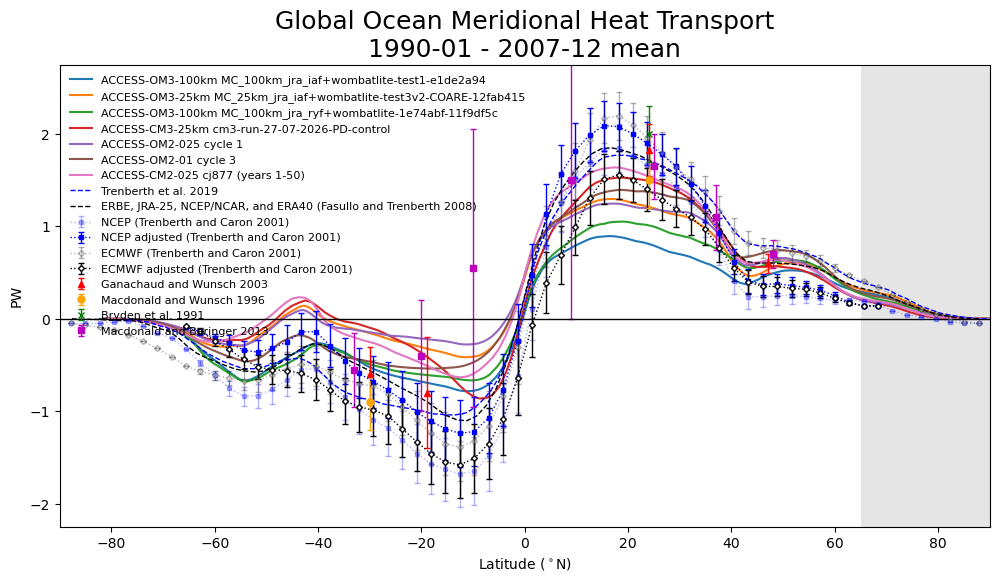

In [33]:
fig = plt.figure(figsize=(12, 6))

# MHT from model outputs
for e, MHT in MHT_OM3_25k.items():
    (MHT.mean('time')/1e15).plot(x = 'yq', label = mlabel(e))
(MHT_OM2_025.mean('time')/1e15).plot(x = 'yu_ocean', label = 'ACCESS-OM2-025 cycle 1')
(MHT_OM2_01.mean('time')/1e15).plot(x = 'yu_ocean', label = 'ACCESS-OM2-01 cycle 3')
MHT_CM2_025_mean.plot(x = 'yu_ocean', label = 'ACCESS-CM2-025 cj877 (years 1-50)')

# observations and error bars for observations

plt.plot(TZFC19['Lat'], TZFC19['Annual'], 'b--', linewidth=1, label="Trenberth et al. 2019")

plt.plot(FT08['Lat'], FT08['Ocn'], 'k--', linewidth=1, label="ERBE, JRA-25, NCEP/NCAR, and ERA40 (Fasullo and Trenberth 2008)")

plt.errorbar(TC01['lats'], TC01['OTn'], yerr=TC01['ERnT'], c='blue', fmt='s:', alpha=0.3,
             markerfacecolor='blue', markersize=3, capsize=2, linewidth=1, label="NCEP (Trenberth and Caron 2001)")
plt.errorbar(TC01['lats'], TC01['OTna'], yerr=TC01['ERnT'], c='blue', fmt='s:', 
             markerfacecolor='blue', markersize=3, capsize=2, linewidth=1, label="NCEP adjusted (Trenberth and Caron 2001)")
plt.errorbar(TC01['lats'], TC01['OTe'], yerr=TC01['EReT'], c='k', fmt='D:', alpha=0.3, 
             markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECMWF (Trenberth and Caron 2001)")
plt.errorbar(TC01['lats'], TC01['OTea'], yerr=TC01['EReT'], c='k', fmt='D:', 
             markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECMWF adjusted (Trenberth and Caron 2001)")

# Ganachaud, A. and Wunsch, C. (2003). Large-scale ocean heat and freshwater transports during the World Ocean Circulation Experiment. Journal of Climate, 16(4):696–705.
# http://dx.doi.org/10.1175/1520-0442(2003)016<0696:LSOHAF>2.0.CO;2
plt.errorbar( [24, -30, -19, 47], [1.83, -0.6, -0.8, 0.6], yerr=[0.28, 0.3, 0.6, 0.1], fmt='^', c='red',   markersize=4, capsize=2, linewidth=1,
             label="Ganachaud and Wunsch 2003")

# Macdonald, A. M. and Wunsch, C. (1996). An estimate of global ocean circulation and heat fluxes. Nature, 382(6590):436–439.
# http://dx.doi.org/10.1038/382436a0
plt.errorbar( [24, -30],  [1.5, -0.9],  yerr=[0.3, 0.3],  fmt='o', c='orange', markersize=5, capsize=2, linewidth=1,
             label="Macdonald and Wunsch 1996")

# Bryden, H. L., Roemmich, D. H., and Church, J. A. (1991). Ocean heat transport across 24◦N in the Pacific. Deep Sea Research Part A. Oceanographic Research Papers, 38(3):297–324.
# http://dx.doi.org/10.1016/0198-0149(91)90070-V
plt.errorbar( 24,  2.0,  yerr=0.3,  fmt='x', c='green', markersize=5, capsize=2, linewidth=1,
             label="Bryden et al. 1991")
             # label="Lavin et al. and Bryden et al. 1991")  # what's the Lavin reference??

# # MacDonald and Baringer data eyeballed from Tsujino Fig 17 https://gmd.copernicus.org/articles/13/3643/2020/#&gid=1&pid=1
# # original source: https://www.sciencedirect.com/science/chapter/bookseries/abs/pii/B9780123918512000295
plt.errorbar( [-33,-20,-10,9,25,37,48], [-0.55,-0.4,0.55,1.5,1.65,1.1,0.7], yerr=[0.4,0.6,1.5,1.5,0.35,0.35,0.15], fmt='s', c='m',   markersize=4, capsize=2, linewidth=1,
             label="Macdonald and Baringer 2013")

plt.xlim(-90, 90)
plt.axvspan(65, 90, facecolor="k", alpha=0.1)  # shade tripolar region, where sum is not zonal
plt.legend(frameon=False, fontsize=8, loc="upper left")
plt.axhline(y=0, linewidth=1, color='black')

plt.ylim(-2.25, 2.75)

plt.title(f"Global Ocean Meridional Heat Transport\n{datestart.strftime('%Y-%m')} - {datestop.strftime('%Y-%m')} mean", fontsize=18)
plt.xlabel('Latitude ($^\circ$N)')
plt.ylabel('PW');

mkmd.savefig(fig, "Meridional Heat Transport", "Global ocean meridional heat transport. [GitHub issue: Total meridional heat transport](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/12)")

### Regional split up into Indo-Pacific and Atlantic sectors

Create a mask for each region before doing a zonal integral

Follow the method in COSIMA-Recipes https://github.com/COSIMA/cosima-recipes/blob/main/03-Advanced-Recipes/Overturning_Circulation.ipynb

(Difficult to say where the boundaries are in https://journals.ametsoc.org/view/journals/clim/32/14/jcli-d-18-0872.1.xml and https://gmd.copernicus.org/articles/13/3643/2020/#&gid=1&pid=1, so just use COSIMA Recipes boundaries)

##### First, do OM3 25km

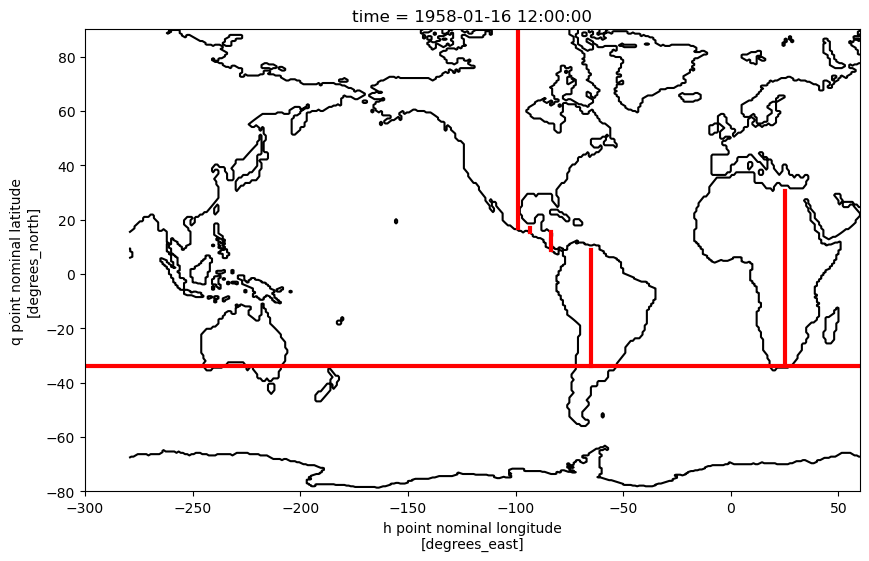

In [34]:
land_mask = ~T_ady_2d.T_ady_2d.isel(time = 0).isnull()

fig = plt.figure(2, (10, 6))
ax = plt.subplot()

land_mask.plot.contour(levels=[0.5], colors='k')

ax.plot([-300, 60], [-34,-34], 'r', linewidth = 3)
ax.plot([-65, -65], [-34, 9], 'r', linewidth = 3)
ax.plot([-83.7, -83.7], [9, 15.5], 'r', linewidth = 3)
ax.plot([-93.3, -93.3], [15.5, 17], 'r', linewidth = 3)
ax.plot([-99, -99], [17, 90], 'r', linewidth = 3)
ax.plot([25, 25], [-34,30.5], 'r', linewidth = 3)
ax.plot([79, 79], [30.5, 90], 'r', linewidth = 3)

ax.set_xlim([-300, 60])
ax.set_ylim([-80, 90]);

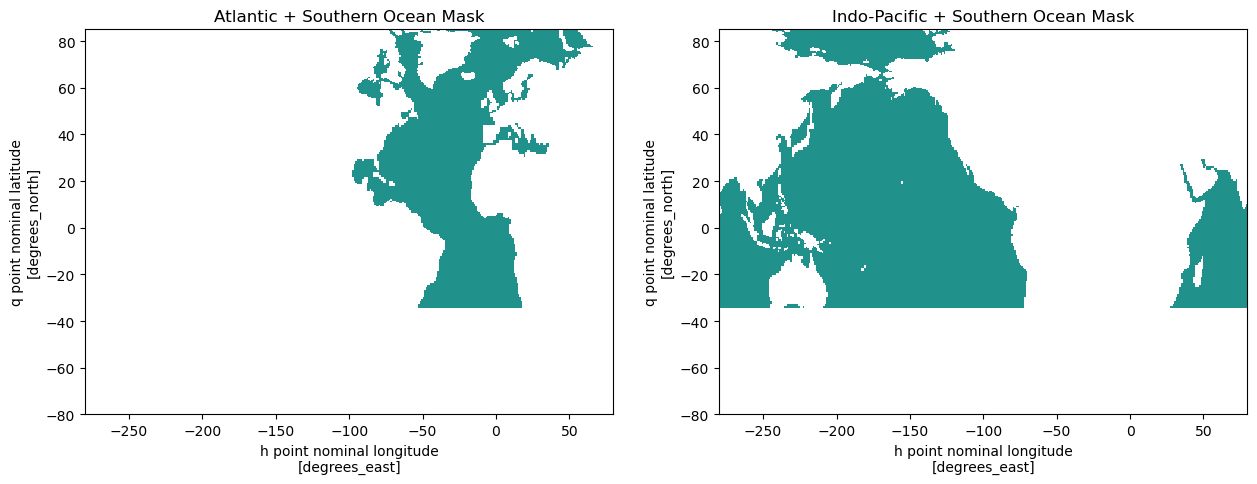

In [35]:
## create masks out of the above chunks
south_map = (land_mask.where(land_mask.yq < -34)).fillna(0)
indo_map1 = (land_mask.where(land_mask.yq < 9).where(land_mask.yq > -34).where(land_mask.xh > -280).where(land_mask.xh < -65)).fillna(0)
indo_map2 = (land_mask.where(land_mask.yq < 15).where(land_mask.yq > 9).where(land_mask.xh > -280).where(land_mask.xh < -83.7)).fillna(0)
indo_map3 = (land_mask.where(land_mask.yq < 17).where(land_mask.yq > 15).where(land_mask.xh > -280).where(land_mask.xh < -93.3)).fillna(0)
indo_map4 = (land_mask.where(land_mask.yq < 85).where(land_mask.yq > 17).where(land_mask.xh > -280).where(land_mask.xh < -99)).fillna(0)
indo_map5 = (land_mask.where(land_mask.yq < 30.5).where(land_mask.yq > -34).where(land_mask.xh > 25).where(land_mask.xh < 80)).fillna(0)

indo_sector_map = indo_map1 + indo_map2 + indo_map3 + indo_map4 + indo_map5 #+ south_map
indo_sector_mask = indo_sector_map.where(indo_sector_map>0)

atlantic_sector_map = (indo_sector_mask * 0).fillna(1) * land_mask
atlantic_sector_map = atlantic_sector_map - south_map
atlantic_sector_mask = atlantic_sector_map.where(atlantic_sector_map > 0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

atlantic_sector_mask.plot(ax=ax[0], add_colorbar=False)
ax[0].set_ylim([-80, 85])
ax[0].set_title('Atlantic + Southern Ocean Mask')

indo_sector_mask.plot(ax=ax[1], add_colorbar=False)
ax[1].set_ylim([-80, 85])
ax[1].set_title('Indo-Pacific + Southern Ocean Mask');


##### Repeat for OM2 25km

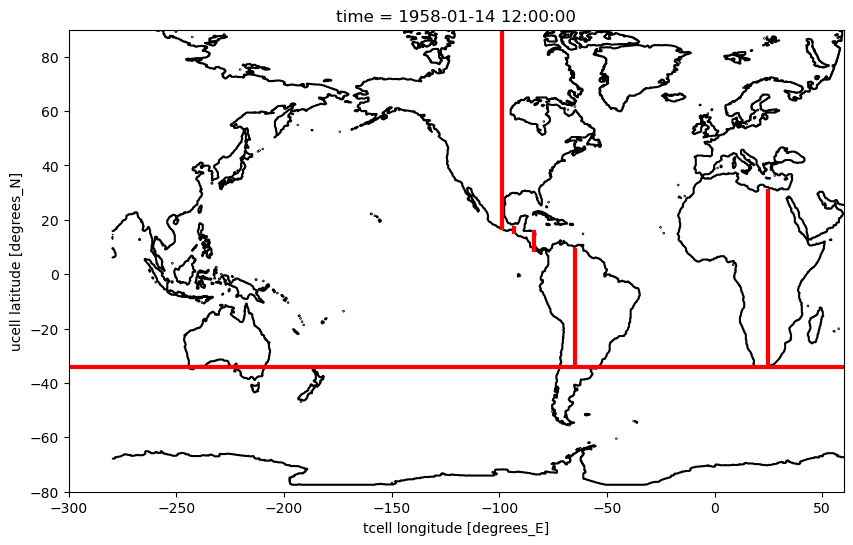

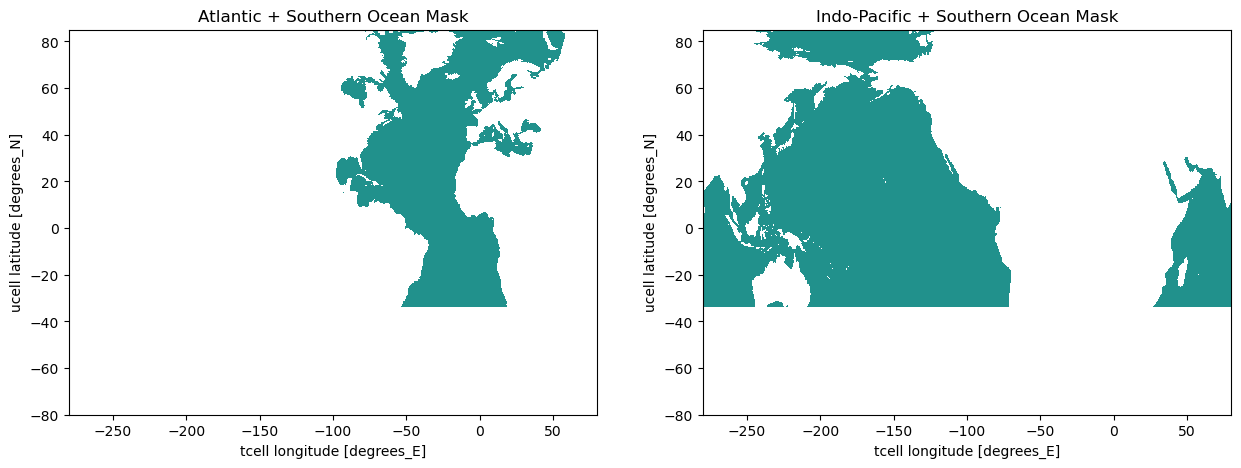

In [36]:
# repeat for OM2

MHT_OM2_025 = temp_yflux_adv_int_z_cycle1 \
                 + temp_yflux_gm_int_z_cycle1 \
                 + temp_yflux_ndiffuse_int_z_cycle1 \
                 + temp_yflux_submeso_int_z_cycle1

land_mask_om2 = ~temp_yflux_adv_int_z_cycle1.isel(time = 0).isnull()

fig = plt.figure(2, (10, 6))
ax = plt.subplot()

land_mask_om2.plot.contour(levels=[0.5], colors='k')

ax.plot([-300, 60], [-34,-34], 'r', linewidth = 3)
ax.plot([-65, -65], [-34, 9], 'r', linewidth = 3)
ax.plot([-83.7, -83.7], [9, 15.5], 'r', linewidth = 3)
ax.plot([-93.3, -93.3], [15.5, 17], 'r', linewidth = 3)
ax.plot([-99, -99], [17, 90], 'r', linewidth = 3)
ax.plot([25, 25], [-34,30.5], 'r', linewidth = 3)
ax.plot([79, 79], [30.5, 90], 'r', linewidth = 3)

ax.set_xlim([-300, 60])
ax.set_ylim([-80, 90]);
plt.show()

## create masks out of the above chunks
south_map_om2 = (land_mask_om2.where(land_mask_om2.yu_ocean < -34)).fillna(0)
indo_map1_om2 = (land_mask_om2.where(land_mask_om2.yu_ocean < 9).where(land_mask_om2.yu_ocean > -34).where(land_mask_om2.xt_ocean > -280).where(land_mask_om2.xt_ocean < -65)).fillna(0)
indo_map2_om2 = (land_mask_om2.where(land_mask_om2.yu_ocean < 15).where(land_mask_om2.yu_ocean > 9).where(land_mask_om2.xt_ocean > -280).where(land_mask_om2.xt_ocean < -83.7)).fillna(0)
indo_map3_om2 = (land_mask_om2.where(land_mask_om2.yu_ocean < 17).where(land_mask_om2.yu_ocean > 15).where(land_mask_om2.xt_ocean > -280).where(land_mask_om2.xt_ocean < -93.3)).fillna(0)
indo_map4_om2 = (land_mask_om2.where(land_mask_om2.yu_ocean < 85).where(land_mask_om2.yu_ocean > 17).where(land_mask_om2.xt_ocean > -280).where(land_mask_om2.xt_ocean < -99)).fillna(0)
indo_map5_om2 = (land_mask_om2.where(land_mask_om2.yu_ocean < 30.5).where(land_mask_om2.yu_ocean > -34).where(land_mask_om2.xt_ocean > 25).where(land_mask_om2.xt_ocean < 80)).fillna(0)

indo_sector_map_om2 = indo_map1_om2 + indo_map2_om2 + indo_map3_om2 + indo_map4_om2 + indo_map5_om2 #+ south_map
indo_sector_mask_om2 = indo_sector_map_om2.where(indo_sector_map_om2>0)

atlantic_sector_map_om2 = (indo_sector_mask_om2 * 0).fillna(1) * land_mask_om2
atlantic_sector_map_om2 = atlantic_sector_map_om2 - south_map_om2
atlantic_sector_mask_om2 = atlantic_sector_map_om2.where(atlantic_sector_map_om2 > 0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

atlantic_sector_mask_om2.plot(ax=ax[0], add_colorbar=False)
ax[0].set_ylim([-80, 85])
ax[0].set_title('Atlantic + Southern Ocean Mask')

indo_sector_mask_om2.plot(ax=ax[1], add_colorbar=False)
ax[1].set_ylim([-80, 85])
ax[1].set_title('Indo-Pacific + Southern Ocean Mask');


##### Repeat for ACCESS-OM2-01

In [37]:
experiment = '01deg_jra55v140_iaf_cycle3'
cat_subset = catalog[experiment]

var_search = cat_subset.search(variable='temp_yflux_adv_int_z')
darray = var_search.to_dask(xarray_open_kwargs={
            "decode_timedelta": False,
            'chunks': "auto"
        })
temp_yflux_adv_int_z_cycle1_01 = darray['temp_yflux_adv_int_z']

# var_search = cat_subset.search(variable='temp_yflux_submeso_int_z')
# darray = var_search.to_dask(xarray_open_kwargs={
#             "decode_timedelta": False,
#             'chunks': "auto"
#         })
# temp_yflux_submeso_int_z_cycle1_01 = darray['temp_yflux_submeso_int_z']

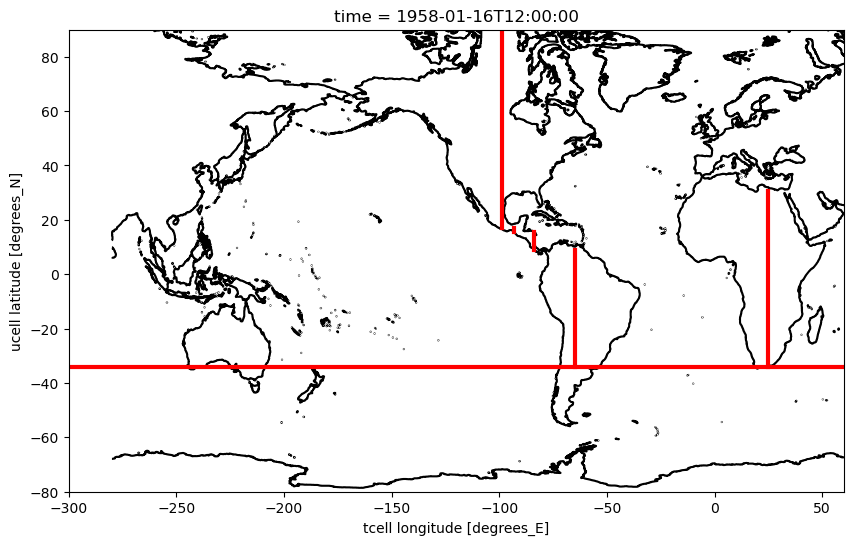

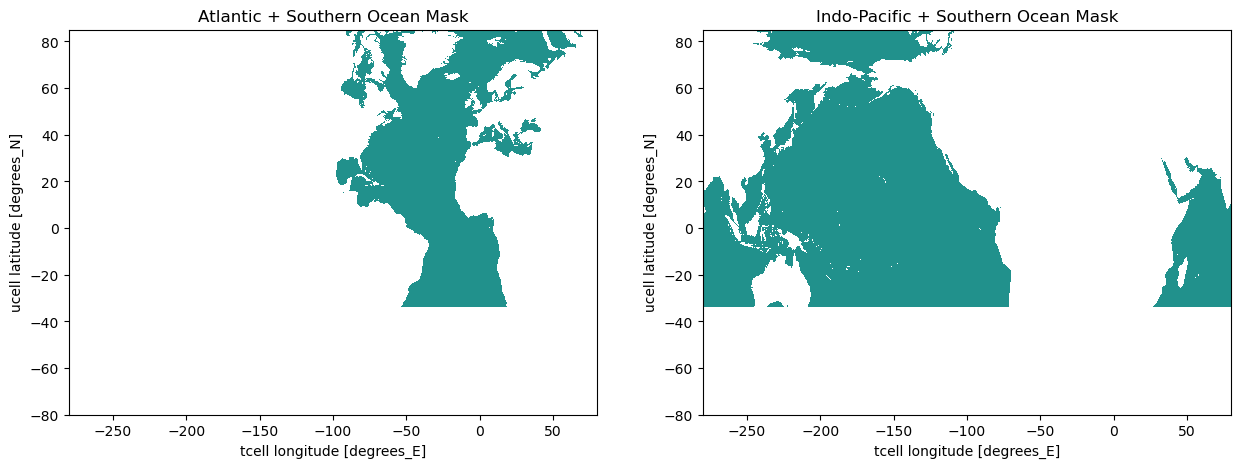

In [38]:
# repeat for OM2_01

MHT_OM2_01 = temp_yflux_adv_int_z_cycle1_01 #\
                 #+ temp_yflux_submeso_int_z_cycle1_01

land_mask_om2_01 = ~temp_yflux_adv_int_z_cycle1_01.isel(time = 0).isnull()

fig = plt.figure(2, (10, 6))
ax = plt.subplot()

land_mask_om2_01.plot.contour(levels=[0.5], colors='k')

ax.plot([-300, 60], [-34,-34], 'r', linewidth = 3)
ax.plot([-65, -65], [-34, 9], 'r', linewidth = 3)
ax.plot([-83.7, -83.7], [9, 15.5], 'r', linewidth = 3)
ax.plot([-93.3, -93.3], [15.5, 17], 'r', linewidth = 3)
ax.plot([-99, -99], [17, 90], 'r', linewidth = 3)
ax.plot([25, 25], [-34,30.5], 'r', linewidth = 3)
ax.plot([79, 79], [30.5, 90], 'r', linewidth = 3)

ax.set_xlim([-300, 60])
ax.set_ylim([-80, 90]);
plt.show()

## create masks out of the above chunks
south_map_om2_01 = (land_mask_om2_01.where(land_mask_om2_01.yu_ocean < -34)).fillna(0)
indo_map1_om2_01 = (land_mask_om2_01.where(land_mask_om2_01.yu_ocean < 9).where(land_mask_om2_01.yu_ocean > -34).where(land_mask_om2_01.xt_ocean > -280).where(land_mask_om2_01.xt_ocean < -65)).fillna(0)
indo_map2_om2_01 = (land_mask_om2_01.where(land_mask_om2_01.yu_ocean < 15).where(land_mask_om2_01.yu_ocean > 9).where(land_mask_om2_01.xt_ocean > -280).where(land_mask_om2_01.xt_ocean < -83.7)).fillna(0)
indo_map3_om2_01 = (land_mask_om2_01.where(land_mask_om2_01.yu_ocean < 17).where(land_mask_om2_01.yu_ocean > 15).where(land_mask_om2_01.xt_ocean > -280).where(land_mask_om2_01.xt_ocean < -93.3)).fillna(0)
indo_map4_om2_01 = (land_mask_om2_01.where(land_mask_om2_01.yu_ocean < 85).where(land_mask_om2_01.yu_ocean > 17).where(land_mask_om2_01.xt_ocean > -280).where(land_mask_om2_01.xt_ocean < -99)).fillna(0)
indo_map5_om2_01 = (land_mask_om2_01.where(land_mask_om2_01.yu_ocean < 30.5).where(land_mask_om2_01.yu_ocean > -34).where(land_mask_om2_01.xt_ocean > 25).where(land_mask_om2_01.xt_ocean < 80)).fillna(0)

indo_sector_map_om2_01 = indo_map1_om2_01 + indo_map2_om2_01 + indo_map3_om2_01 + indo_map4_om2_01 + indo_map5_om2_01 #+ south_map
indo_sector_mask_om2_01 = indo_sector_map_om2_01.where(indo_sector_map_om2_01>0)

atlantic_sector_map_om2_01 = (indo_sector_mask_om2_01 * 0).fillna(1) * land_mask_om2_01
atlantic_sector_map_om2_01 = atlantic_sector_map_om2_01 - south_map_om2_01
atlantic_sector_mask_om2_01 = atlantic_sector_map_om2_01.where(atlantic_sector_map_om2_01 > 0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

atlantic_sector_mask_om2_01.plot(ax=ax[0], add_colorbar=False)
ax[0].set_ylim([-80, 85])
ax[0].set_title('Atlantic + Southern Ocean Mask')

indo_sector_mask_om2_01.plot(ax=ax[1], add_colorbar=False)
ax[1].set_ylim([-80, 85])
ax[1].set_title('Indo-Pacific + Southern Ocean Mask');


##### Load basin-based observations

In [39]:
# load basin based obs

filename = '/g/data/ik11/observations/TrenberthZhangFasulloCheng2019/Fig_6c_2000_2016_monthly_ZonalSum_MeanAnnualCycle_AtlanticArctic_0-2000m_ensemble_mean_withSeaIce.txt'
TZFC19At = read_csv(filename, delimiter='\s+', skiprows=3, na_values='MMM',
                 names=['Lat', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Annual'])

TZFC19At

filename = '/g/data/ik11/observations/TrenberthZhangFasulloCheng2019/Fig_4b_and_6b_2000_2016_monthly_ZonalSum_MeanAnnualCycle_Indo-Pacific_0-2000m_ensemble_mean.txt'
TZFC19IP = read_csv(filename, delimiter='\s+', skiprows=3, na_values='MMM',
                 names=['Lat', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Annual'])


##### Plot together:


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport_06.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100B/mkmd/MeridionalHeatTransport.md successfully.


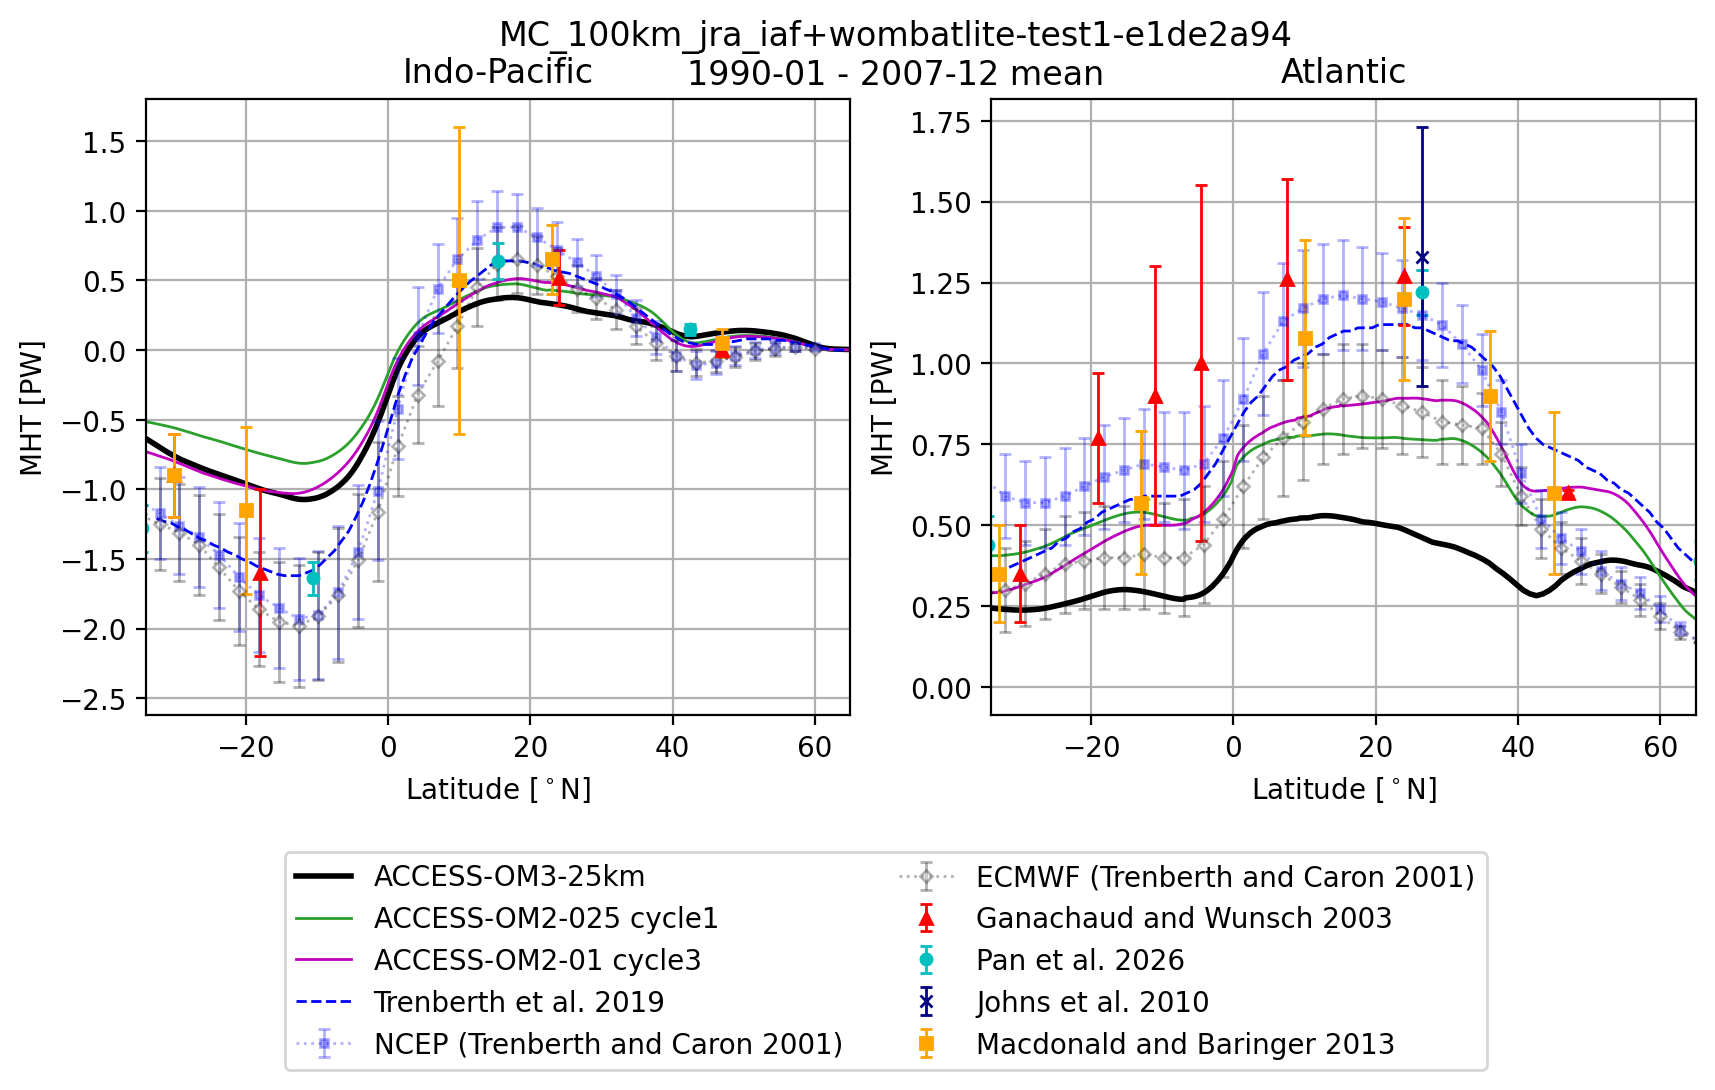

In [40]:
fig, axes = plt.subplots(ncols = 2, figsize = (10,4),dpi = 200)

ax = axes[0]

T_ady_2d_IP = (T_ady_2d.T_ady_2d.sel(time = timeslice)*indo_sector_mask).sum('xh').mean('time').load()/1e15
T_diffy_2d_IP = (T_diffy_2d.T_diffy_2d.sel(time = timeslice)*indo_sector_mask).sum('xh').mean('time').load()/1e15

(T_ady_2d_IP + T_diffy_2d_IP).where(T_ady_2d_IP.yq>-34).plot(ax = ax, label = 'ACCESS-OM3-25km', color = 'k', linewidth=2)

mht_om2_IP = (MHT_OM2_025.sel(time = om2timeslice)*indo_sector_mask_om2).sum('xt_ocean').mean('time').load()/1e15
mht_om2_IP.where(mht_om2_IP.yu_ocean>-34).plot(ax = ax, label = 'ACCESS-OM2-025 cycle1', color = 'C2', linewidth=1)

mht_om2_IP_01 = (MHT_OM2_01.sel(time = slice('1990-01-01','2018-12-31'))*indo_sector_mask_om2_01).sum('xt_ocean').mean('time').load()/1e15
mht_om2_IP_01.where(mht_om2_IP_01.yu_ocean>-34).plot(ax = ax, label = 'ACCESS-OM2-01 cycle3', color = 'm', linewidth=1)
#T_ady_2d_IP.plot(ax = ax,label = 'Advective')
#T_diffy_2d_IP.plot(ax = ax,label = 'Diffusive')
ax.errorbar(TC01['lats'], TC01['PACn']+np.nan_to_num(TC01['INDn'],nan = 0), yerr=TC01['ERnP']+np.nan_to_num(TC01['ERnI'],nan=0), c='blue', fmt='s:', alpha=0.3,
             markerfacecolor='blue', markersize=3, capsize=2, linewidth=1, label="NCEP (Trenberth and Caron 2001)")
# plt.errorbar(TC01['lats'], TC01['PACna']+TC01['INDna'], yerr=TC01['ERnP']+TC01['ERnI'], c='blue', fmt='s:', 
#              markerfacecolor='blue', markersize=3, capsize=2, linewidth=1, label="NCEP adjusted (Trenberth and Caron 2001)")
ax.errorbar(TC01['lats'], TC01['PACe']+np.nan_to_num(TC01['INDe'],nan=0), yerr=TC01['EReP']+np.nan_to_num(TC01['EReI'],nan=0), c='k', fmt='D:', alpha=0.3, 
             markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECMWF (Trenberth and Caron 2001)")
# plt.errorbar(TC01['lats'], TC01['PACea']+TC01['INDea'], yerr=TC01['EReP']+TC01['EReI'], c='k', fmt='D:', 
#              markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECMWF adjusted (Trenberth and Caron 2001)")
ax.plot(TZFC19IP['Lat'], TZFC19IP['Annual'], 'b--', linewidth=1, label="Trenberth et al. 2019")

# Ganachaud, A. and Wunsch, C. (2003). Large-scale ocean heat and freshwater transports during the World Ocean Circulation Experiment. Journal of Climate, 16(4):696–705.
# http://dx.doi.org/10.1175/1520-0442(2003)016<0696:LSOHAF>2.0.CO;2
ax.errorbar( [47, 24, -18, -30], [0, 0.52, -1.6, -0.9], yerr=[0.05, 0.2, 0.6, 0.3], fmt='^', c='red',   markersize=4, capsize=2, linewidth=1,
             label="Ganachaud and Wunsch 2003")
# PanChengStortoMayerGulevLiLyuZhengYuan2026a - Table 1 data (averaged 2000-2023)
# https://dx.doi.org/10.1175/JCLI-D-25-0522.1
ax.errorbar( [42.5,15.5,-10.5,-34.5], [0.15, 0.64, -1.64, -1.28], yerr=[0.04,0.13,0.12,0.17], fmt='o', c='c',   markersize=4, capsize=2, linewidth=1,
             label="Pan et al. 2026")
# MacDonald and Baringer data 
# NOTE!! Eyeballed from Tsujino Fig 17 https://gmd.copernicus.org/articles/13/3643/2020/#&gid=1&pid=1
# original source: https://www.sciencedirect.com/science/chapter/bookseries/abs/pii/B9780123918512000295
ax.errorbar( [-30,-20,10,23,47], [-0.9,-1.15,0.5,0.65,0.05], yerr=[0.3,0.6,1.1,0.25,0.1], fmt='s', c='orange',   markersize=4, capsize=2, linewidth=1,
             label="Macdonald and Baringer 2013")

ax.set_title('Indo-Pacific')
ax.set_xlim(-34,65)
ax.set_ylabel('MHT [PW]')
ax.set_xlabel('Latitude [$^\circ$N]')
ax.grid()

ax = axes[1]

T_ady_2d_A = (T_ady_2d.T_ady_2d.sel(time = timeslice)*atlantic_sector_mask).sum('xh').mean('time').load()/1e15
T_diffy_2d_A = (T_diffy_2d.T_diffy_2d.sel(time = timeslice)*atlantic_sector_mask).sum('xh').mean('time').load()/1e15

(T_ady_2d_A + T_diffy_2d_A).where(T_ady_2d_A.yq>-34).plot(ax = ax, label = 'ACCESS-OM3-25km', color = 'k', linewidth=2)

mht_om2_A = (MHT_OM2_025.sel(time = om2timeslice)*atlantic_sector_mask_om2).sum('xt_ocean').mean('time').load()/1e15
mht_om2_A.where(mht_om2_A.yu_ocean>-34).plot(ax = ax, label = 'ACCESS-OM2-025 cycle1', color = 'C2', linewidth=1)

mht_om2_A_01 = (MHT_OM2_01.sel(time = slice('1990-01-01','2018-12-31'))*atlantic_sector_mask_om2_01).sum('xt_ocean').mean('time').load()/1e15
mht_om2_A_01.where(mht_om2_A_01.yu_ocean>-34).plot(ax = ax, label = 'ACCESS-OM2-01 cycle3', color = 'm', linewidth=1)


#T_ady_2d_A.plot(ax = ax,label = 'Advective')
#T_diffy_2d_A.plot(ax = ax,label = 'Diffusive')
ax.errorbar(TC01['lats'], TC01['ATLn'], yerr=TC01['ERnA'], c='blue', fmt='s:', alpha=0.3,
             markerfacecolor='blue', markersize=3, capsize=2, linewidth=1, label="NCEP (Trenberth and Caron 2001)")
# plt.errorbar(TC01['lats'], TC01['ATna'], yerr=TC01['ERnA'], c='blue', fmt='s:', 
#              markerfacecolor='blue', markersize=3, capsize=2, linewidth=1, label="NCEP adjusted (Trenberth and Caron 2001)")
ax.errorbar(TC01['lats'], TC01['ATLe'], yerr=TC01['EReA'], c='k', fmt='D:', alpha=0.3, 
             markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECMWF (Trenberth and Caron 2001)")
# plt.errorbar(TC01['lats'], TC01['ATea'], yerr=TC01['EReA'], c='k', fmt='D:', 
#              markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECMWF adjusted (Trenberth and Caron 2001)")
ax.plot(TZFC19At['Lat'], TZFC19At['Annual'], 'b--', linewidth=1, label="Trenberth et al. 2019")

# Ganachaud, A. and Wunsch, C. (2003). Large-scale ocean heat and freshwater transports during the World Ocean Circulation Experiment. Journal of Climate, 16(4):696–705.
# http://dx.doi.org/10.1175/1520-0442(2003)016<0696:LSOHAF>2.0.CO;2
ax.errorbar( [47, 24, 7.5, -4.5, -11, -19, -30], [0.6, 1.27, 1.26, 1, 0.9, 0.77, 0.35], 
             yerr=[0.009, 0.15, 0.31, 0.55, 0.4, 0.2, 0.15], fmt='^', c='red',   markersize=4, capsize=2, linewidth=1,
             label="Ganachaud and Wunsch 2003")
# PanChengStortoMayerGulevLiLyuZhengYuan2026a - Table 1 data (averaged 2000-2023)
# https://dx.doi.org/10.1175/JCLI-D-25-0522.1
ax.errorbar( [65.6,26.5,-34.5], [0.39,1.22,0.44], yerr=[0.06,0.07,0.09], fmt='o', c='c',   markersize=4, capsize=2, linewidth=1,
             label="Pan et al. 2026")
# JohnsETAL2011a http://dx.doi.org/10.1175/2010JCLI3997.1
ax.errorbar( [26.5], [1.33], yerr=[0.4], fmt='x', c='navy',   markersize=4, capsize=2, linewidth=1,
             label="Johns et al. 2010")
# MacDonald and Baringer data eyeballed from Tsujino Fig 17 https://gmd.copernicus.org/articles/13/3643/2020/#&gid=1&pid=1
# original source: https://www.sciencedirect.com/science/chapter/bookseries/abs/pii/B9780123918512000295
ax.errorbar( [-33,-13,10,24,36,45], [0.35,0.57,1.08,1.2,0.9,0.6], yerr=[0.15,0.22,0.3,0.25,0.2,0.25], fmt='s', c='orange',   markersize=4, capsize=2, linewidth=1,
             label="Macdonald and Baringer 2013")


ax.set_title('Atlantic')
ax.set_xlim(-34,65)
ax.grid()
ax.set_ylabel('MHT [PW]')
ax.set_xlabel('Latitude [$^\circ$N]')

plt.legend(loc = 'upper center', ncol = 2, bbox_to_anchor = (-0.15,-0.2))

fig.suptitle(f"{exptname}\n{T_ady_2d.sel(time = timeslice).time.values[0].strftime('%Y-%m')} - {T_ady_2d.sel(time = timeslice).time.values[-1].strftime('%Y-%m')} mean")

mkmd.savefig(fig, "Meridional Heat Transport", "Global ocean meridional heat transport split into basins. [GitHub issue: Total meridional heat transport](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/12)")

In [41]:
client.close()